# ICU Transfer Prediction — Preprocessing and EDA
**MIMIC-IV | IE 7275 Group Project**







## 1. Load the data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Folder containing the datasets
DATA = Path(r"C:\Users\Owner\OneDrive\Documents\ICU_Project\Data")

# List of CSV files
files = [
    "admissions_all.csv",
    "cohort.csv",
    "transfers.csv",
    "features.csv",
    "split.csv",
    "labs.csv",
    "omr.csv",
    "diagnoses.csv",
    "prescriptions.csv",
    "services.csv"
]

# Check available files
for file in files:
    print(file, (DATA / file).exists())

# Load prepared dataset for EDA
df = pd.read_csv(DATA / "features.csv")

print(df.shape)
df.head()

admissions_all.csv True
cohort.csv True
transfers.csv True
features.csv True
split.csv True
labs.csv True
omr.csv True
diagnoses.csv True
prescriptions.csv True
services.csv True
(852813, 142)


,subject_id,hadm_id,snapshot_time,y_24h,y_48h,age,gender_male,admission_type,admission_location,careunit,...,lactate_count24h,magnesium_count24h,pco2_count24h,ph_count24h,platelets_count24h,po2_count24h,potassium_count24h,sodium_count24h,troponin_t_count24h,wbc_count24h
0,10000032,22841357,2180-06-27 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0
1,10000032,25742920,2180-08-06 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0
2,10000032,25742920,2180-08-07 08:00:00,0,0,52,0,EW EMER.,EMERGENCY ROOM,Transplant,...,0.0,1.0,0.0,0.0,1.0,0.0,2.0,1.0,0.0,1.0
3,10000690,23280645,2150-09-17 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,10000690,23280645,2150-09-18 08:00:00,0,0,86,0,EW EMER.,EMERGENCY ROOM,Thoracic Surgery,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,2.0,1.0


## 2. Check and clean the data
As in Lab 1: look at data types, repeated records, and missing values. Don't fill missing lab values yet.

In [5]:
df.info()
print("\nExact duplicates:", df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Repeated snapshot keys:", df.duplicated(["hadm_id", "snapshot_time"]).sum())

print("\nMissing values (top 15 columns):")
print(df.isna().sum().sort_values(ascending=False).head(15))

# Each admission and prediction time should identify one snapshot.
if df.duplicated(["hadm_id", "snapshot_time"]).any():
    raise ValueError("Repeated snapshot keys: check the source data before proceeding.")

<class 'pandas.DataFrame'>
RangeIndex: 852813 entries, 0 to 852812
Columns: 142 entries, subject_id to wbc_count24h
dtypes: float64(121), int64(16), str(5)
memory usage: 923.9 MB

Exact duplicates: 0
Repeated snapshot keys: 0

Missing values (top 15 columns):
pco2_min24h          837554
pco2_max24h          837554
po2_max24h           837547
po2_min24h           837547
ph_min24h            834550
ph_max24h            834550
troponin_t_max24h    829741
troponin_t_min24h    829741
lactate_min24h       823401
lactate_max24h       823401
po2_delta            822779
pco2_delta           822752
ph_delta             816814
troponin_t_delta     806105
lactate_delta        801014
dtype: int64


## 3. Check patient selection and ICU targets


In [6]:
# Adult patients with at least one prior admission during the last 365 days.
needed = ["subject_id", "hadm_id", "snapshot_time", "age", "n_prior_adm_365d",
          "days_since_prev_disch", "hours_since_admit", "careunit", "y_24h", "y_48h"]
needed += [x + "_last" for x in ["creatinine", "glucose", "hemoglobin", "lactate", "sodium", "wbc"]]
missing_columns = [col for col in needed if col not in df.columns]
if missing_columns:
    raise ValueError("Missing columns in features.csv: " + ", ".join(missing_columns))

before = len(df)
df = df[(df["age"] >= 18) & (df["n_prior_adm_365d"] >= 1) &
        (df["hours_since_admit"] >= 0) & df["careunit"].notna()].copy()
df = df.dropna(subset=["snapshot_time", "y_24h", "y_48h"])
print("Snapshots before basic checks:", before)
print("Snapshots after basic checks:", len(df))
print("Patients:", df["subject_id"].nunique())
print("Admissions:", df["hadm_id"].nunique())

# A transfer within 24 hours must also count as a transfer within 48 hours.
assert df["y_24h"].isin([0, 1]).all() and df["y_48h"].isin([0, 1]).all()
assert (df["y_24h"] <= df["y_48h"]).all()
print("\n24-hour ICU labels:\n", df["y_24h"].value_counts())
print("\n48-hour ICU labels:\n", df["y_48h"].value_counts())

# Names used in the charts below.
lab_names = ["creatinine_last", "glucose_last", "hemoglobin_last",
             "lactate_last", "sodium_last", "wbc_last"]

Snapshots before basic checks: 852813
Snapshots after basic checks: 852813
Patients: 62528
Admissions: 163561

24-hour ICU labels:
 y_24h
0    845970
1      6843
Name: count, dtype: int64

48-hour ICU labels:
 y_48h
0    841202
1     11611
Name: count, dtype: int64


## 4. Summary statistics and outliers
Use `describe()` and the **IQR** and **Z-score** methods from Lab 1. An unusual clinical result is not automatically an error.

In [7]:
numeric_features = ["age", "days_since_prev_disch", "n_prior_adm_365d",
                    "hours_since_admit"] + lab_names
print(df[numeric_features].describe().round(2))
print("\nMissing percentages:\n", (df[numeric_features].isna().mean() * 100).round(1))

# Two simple methods for spotting extreme values.
for name in ["age", "lactate_last"]:
    values = df[name].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_count = ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum()
    z = (values - values.mean()) / values.std() if values.std() > 0 else values * 0
    print(name, "— IQR flags:", iqr_count, "; Z-score flags:", (z.abs() > 3).sum())

             age  days_since_prev_disch  n_prior_adm_365d  hours_since_admit  \
count  852813.00              852813.00         852813.00          852813.00   
mean       60.88                  62.55              2.80             168.26   
std        18.01                  84.75              2.71             291.60   
min        18.00                   0.00              1.00               0.02   
25%        49.00                   5.47              1.00              35.75   
50%        63.00                  23.71              2.00              83.20   
75%        74.00                  84.38              3.00             180.87   
max       102.00                 364.99             56.00            5368.75   

       creatinine_last  glucose_last  hemoglobin_last  lactate_last  \
count        694391.00     689559.00        709560.00     159022.00   
mean              1.41        123.16            10.19          1.60   
std               1.57         54.00             2.05          0.7

## 5. Exploratory Data Analysis


### Figure 1 — Class balance

                 24h     48h
No transfer   845970  841202
ICU transfer    6843   11611


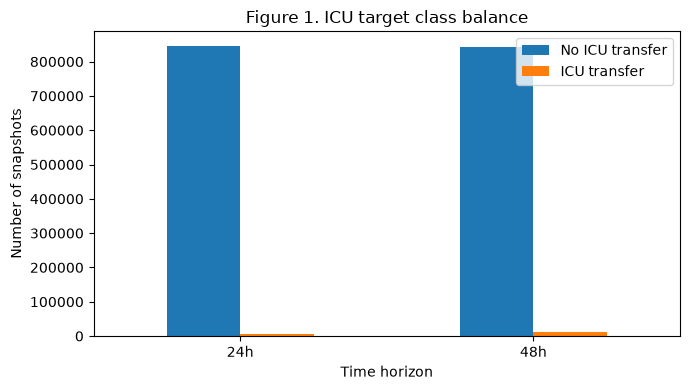

24h transfer rate: 0.8 %
48h transfer rate: 1.36 %


In [8]:
balance = pd.DataFrame({
    "24h": df["y_24h"].value_counts().reindex([0, 1], fill_value=0),
    "48h": df["y_48h"].value_counts().reindex([0, 1], fill_value=0)
})
print(balance.rename(index={0: "No transfer", 1: "ICU transfer"}))

ax = balance.T.plot(kind="bar", figsize=(7, 4), rot=0)
ax.set_title("Figure 1. ICU target class balance")
ax.set_ylabel("Number of snapshots")
ax.set_xlabel("Time horizon")
ax.legend(["No ICU transfer", "ICU transfer"])
plt.tight_layout()
plt.savefig(OUT / "figure_01_class_balance.png", bbox_inches="tight")
plt.show()
print("24h transfer rate:", round(df["y_24h"].mean() * 100, 2), "%")
print("48h transfer rate:", round(df["y_48h"].mean() * 100, 2), "%")

### Figure 2 — Patient and admission features

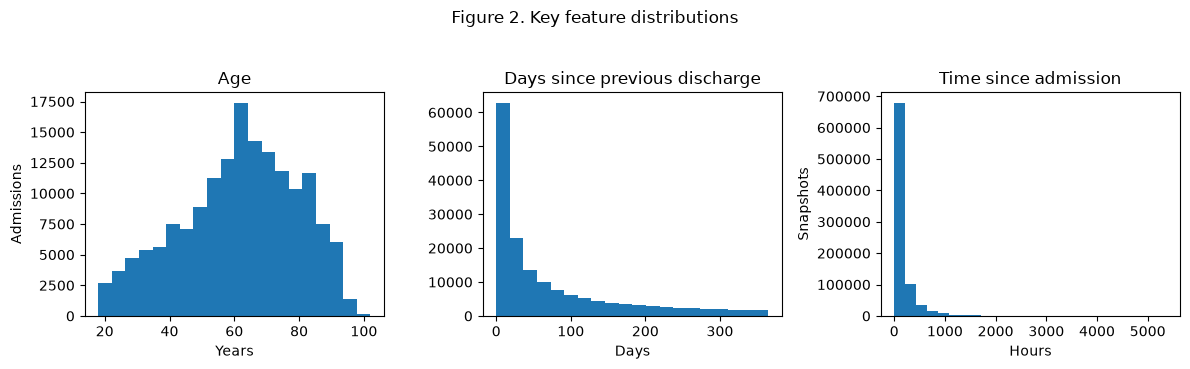

In [9]:
one = df.drop_duplicates("hadm_id")  # Count each admission once for the first two charts.
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].hist(one["age"].dropna(), bins=20)
axes[0].set_title("Age")
axes[0].set_xlabel("Years")
axes[0].set_ylabel("Admissions")

axes[1].hist(one["days_since_prev_disch"].dropna(), bins=20)
axes[1].set_title("Days since previous discharge")
axes[1].set_xlabel("Days")

axes[2].hist(df["hours_since_admit"].dropna(), bins=25)
axes[2].set_title("Time since admission")
axes[2].set_xlabel("Hours")
axes[2].set_ylabel("Snapshots")

fig.suptitle("Figure 2. Key feature distributions", y=1.04)
plt.tight_layout()
plt.savefig(OUT / "figure_02_patient_distributions.png", bbox_inches="tight")
plt.show()

### Figure 3 — Laboratory distributions

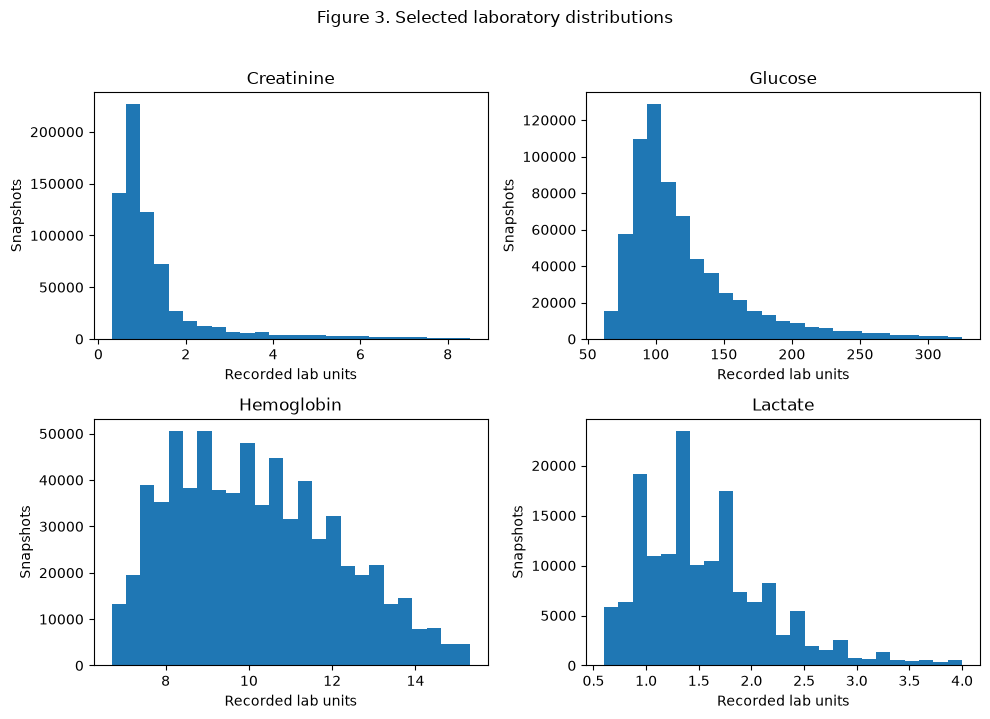

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, name in zip(axes.flat, ["creatinine_last", "glucose_last", "hemoglobin_last", "lactate_last"]):
    values = df[name].dropna()
    if not values.empty:
        low, high = values.quantile([0.01, 0.99])
        ax.hist(values[values.between(low, high)], bins=25)
    ax.set_title(name.replace("_last", "").title())
    ax.set_xlabel("Recorded lab units")
    ax.set_ylabel("Snapshots")

fig.suptitle("Figure 3. Selected laboratory distributions", y=1.02)
plt.tight_layout()
plt.savefig(OUT / "figure_03_labs.png", bbox_inches="tight")
plt.show()

### Figure 4 — Missing laboratory measurements

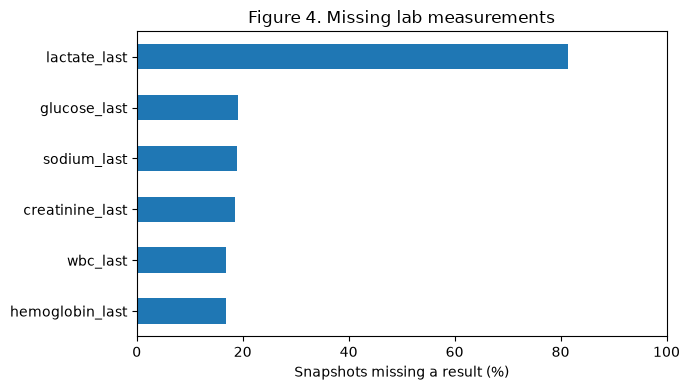

hemoglobin_last    16.8
wbc_last           16.9
creatinine_last    18.6
sodium_last        18.9
glucose_last       19.1
lactate_last       81.4
dtype: float64


In [11]:
missing_pct = (df[lab_names].isna().mean() * 100).sort_values()
ax = missing_pct.plot(kind="barh", figsize=(7, 4))
ax.set_title("Figure 4. Missing lab measurements")
ax.set_xlabel("Snapshots missing a result (%)")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig(OUT / "figure_04_missing_labs.png", bbox_inches="tight")
plt.show()
print(missing_pct.round(1))

### Figure 5 — Features compared with ICU transfer

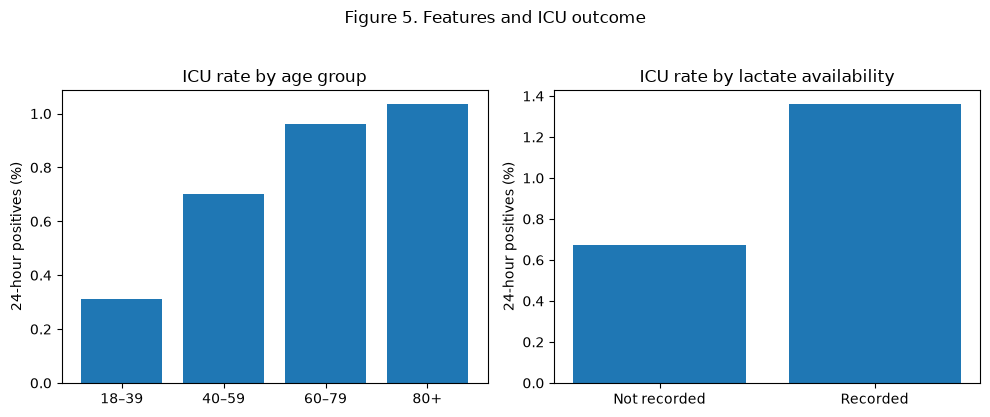

ICU rates by age group:
                mean    size
age_group                  
18–39      0.003119  126650
40–59      0.007009  243840
60–79      0.009617  344700
80+        0.010347  137623
ICU rates by lactate availability:
                  mean    size
has_lactate                  
False        0.006747  693791
True         0.013596  159022


In [12]:
df["age_group"] = pd.cut(df["age"], bins=[18, 40, 60, 80, np.inf],
                         right=False, labels=["18–39", "40–59", "60–79", "80+"])
df["has_lactate"] = df["lactate_last"].notna()

age_table = df.groupby("age_group", observed=True)["y_24h"].agg(["mean", "size"])
lactate_table = df.groupby("has_lactate")["y_24h"].agg(["mean", "size"])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(age_table.index.astype(str), age_table["mean"] * 100)
axes[0].set_title("ICU rate by age group")
axes[0].set_ylabel("24-hour positives (%)")

order = lactate_table.reindex([False, True])
axes[1].bar(["Not recorded", "Recorded"], order["mean"] * 100)
axes[1].set_title("ICU rate by lactate availability")
axes[1].set_ylabel("24-hour positives (%)")

fig.suptitle("Figure 5. Features and ICU outcome", y=1.03)
plt.tight_layout()
plt.savefig(OUT / "figure_05_feature_target.png", bbox_inches="tight")
plt.show()
print("ICU rates by age group:\n", age_table)
print("ICU rates by lactate availability:\n", lactate_table)

### Figure 6 — Correlations between features

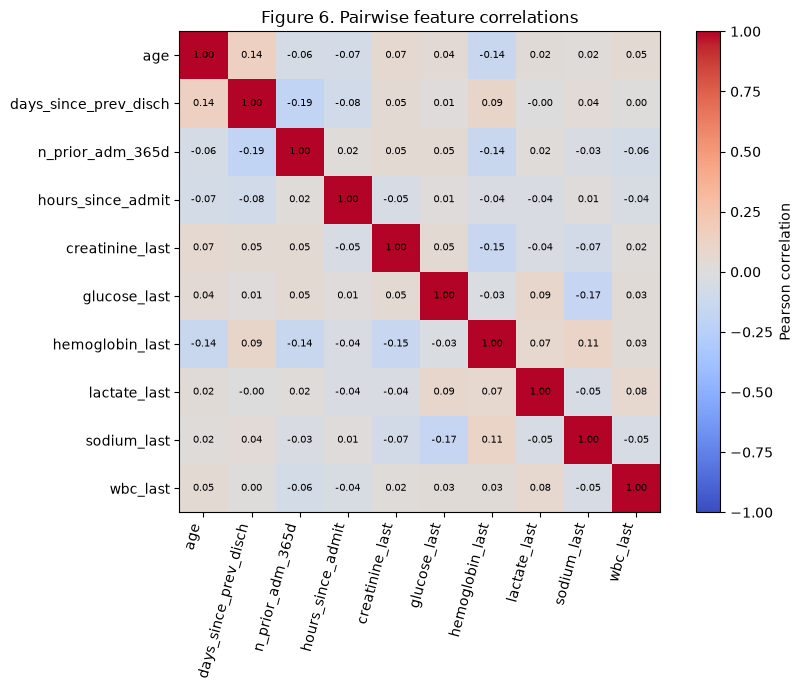

In [13]:
correlation = df[numeric_features].corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_features)), numeric_features, rotation=75, ha="right")
ax.set_yticks(range(len(numeric_features)), numeric_features)

# Write each correlation coefficient inside its square.
for i in range(len(numeric_features)):
    for j in range(len(numeric_features)):
        value = correlation.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7)

ax.set_title("Figure 6. Pairwise feature correlations")
plt.colorbar(im, ax=ax, label="Pearson correlation")
plt.tight_layout()
plt.savefig(OUT / "figure_06_correlations.png", bbox_inches="tight")
plt.show()

### Figure 7 — ICU risk over the hospital stay

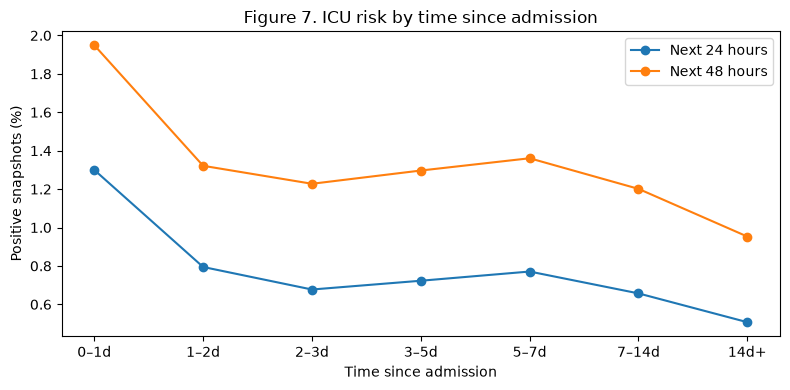

             y_24h  y_48h
stay_period              
0–1d          1.30   1.95
1–2d          0.79   1.32
2–3d          0.68   1.23
3–5d          0.72   1.30
5–7d          0.77   1.36
7–14d         0.66   1.20
14d+          0.51   0.95


In [14]:
df["stay_period"] = pd.cut(df["hours_since_admit"],
    bins=[0, 24, 48, 72, 120, 168, 336, np.inf], right=False,
    labels=["0–1d", "1–2d", "2–3d", "3–5d", "5–7d", "7–14d", "14d+"])

period_table = df.groupby("stay_period", observed=True)[["y_24h", "y_48h"]].mean() * 100
ax = period_table.plot(marker="o", figsize=(8, 4))
ax.set_title("Figure 7. ICU risk by time since admission")
ax.set_xlabel("Time since admission")
ax.set_ylabel("Positive snapshots (%)")
ax.legend(["Next 24 hours", "Next 48 hours"])
plt.tight_layout()
plt.savefig(OUT / "figure_07_time.png", bbox_inches="tight")
plt.show()
print(period_table.round(2))

### Figure 8 — Ward and patient-level structure

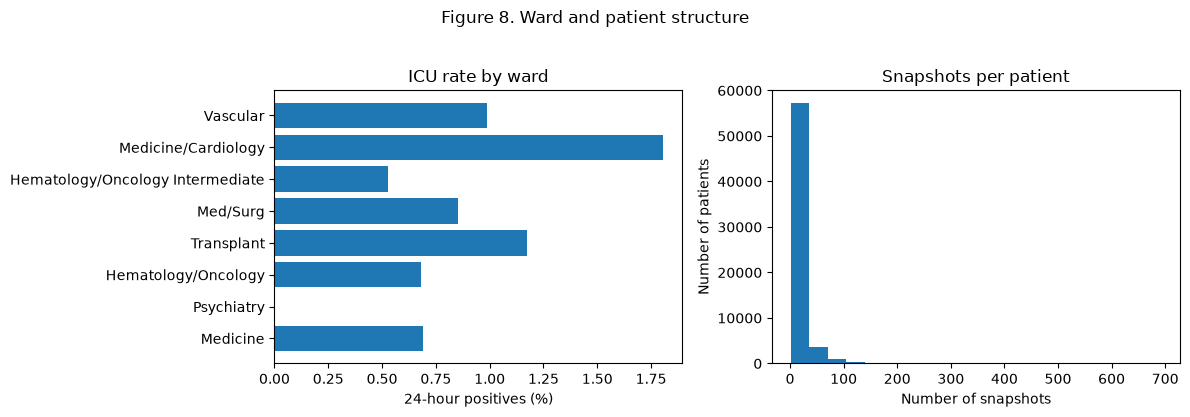

Ward counts and event rates:
                                       mean    size
careunit                                          
Medicine                          0.006890  225531
Psychiatry                        0.000000  102650
Hematology/Oncology               0.006812   83378
Transplant                        0.011711   62506
Med/Surg                          0.008513   57323
Hematology/Oncology Intermediate  0.005290   51986
Medicine/Cardiology               0.018054   48633
Vascular                          0.009864   34571
Snapshots per patient:
 count    62528.0
mean        13.6
std         23.7
min          1.0
25%          3.0
50%          6.0
75%         15.0
max        693.0
dtype: float64


In [16]:
ward_table = df.groupby("careunit")["y_24h"].agg(["mean", "size"])
ward_table = ward_table[ward_table["size"] >= 30].sort_values("size", ascending=False).head(8)
snapshots_per_patient = df.groupby("subject_id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if not ward_table.empty:
    axes[0].barh(ward_table.index.astype(str), ward_table["mean"] * 100)
else:
    axes[0].text(0.1, 0.5, "No wards with 30+ snapshots", transform=axes[0].transAxes)
axes[0].set_title("ICU rate by ward")
axes[0].set_xlabel("24-hour positives (%)")

axes[1].hist(snapshots_per_patient, bins=20)
axes[1].set_title("Snapshots per patient")
axes[1].set_xlabel("Number of snapshots")
axes[1].set_ylabel("Number of patients")

fig.suptitle("Figure 8. Ward and patient structure", y=1.03)
plt.tight_layout()
plt.savefig(OUT / "figure_08_grouping.png", bbox_inches="tight")
plt.show()
print("Ward counts and event rates:\n", ward_table)
print("Snapshots per patient:\n", snapshots_per_patient.describe().round(1))